In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.feature_selection import RFE
from sklearn.metrics import r2_score,mean_squared_error,make_scorer,mean_absolute_error
from sklearn.tree import plot_tree

In [20]:
concret=pd.read_csv('concrete.csv')

In [21]:
concret.head()

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [22]:
concret.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cement        1030 non-null   float64
 1   slag          1030 non-null   float64
 2   ash           1030 non-null   float64
 3   water         1030 non-null   float64
 4   superplastic  1030 non-null   float64
 5   coarseagg     1030 non-null   float64
 6   fineagg       1030 non-null   float64
 7   age           1030 non-null   int64  
 8   strength      1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [23]:
concret.describe()

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [24]:
concret.shape

(1030, 9)

# EDA

In [25]:
## pairplot for each columns vs strength

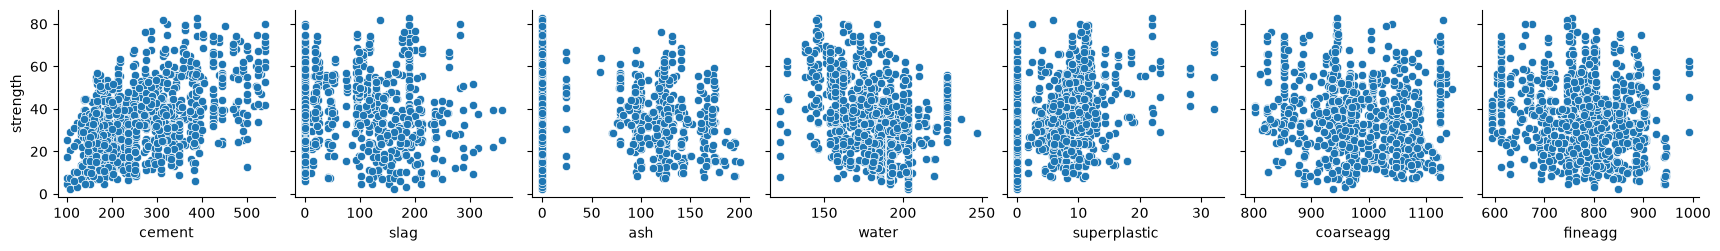

In [26]:
sns.pairplot(x_vars=['cement', 'slag', 'ash', 'water', 'superplastic', 'coarseagg',
       'fineagg'],
    y_vars=['strength'],data=concret
)
plt.show()

In [27]:
## each column non linear so randaom forest use pannum pothu result innum better ah varum

In [28]:
### correlation heat map

In [29]:
correlation=concret.corr()
correlation

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
cement,1.000000,-0.275216,-0.397467,-0.081587,0.092386,-0.109349,-0.222718,0.081946,0.497832
slag,-0.275216,1.000000,-0.323580,0.107252,0.043270,-0.283999,-0.281603,-0.044246,0.134829
ash,-0.397467,-0.323580,1.000000,-0.256984,0.377503,-0.009961,0.079108,-0.154371,-0.105755
water,-0.081587,0.107252,-0.256984,1.000000,-0.657533,-0.182294,-0.450661,0.277618,-0.289633
superplastic,0.092386,0.043270,0.377503,-0.657533,1.000000,-0.265999,0.222691,-0.192700,0.366079
coarseagg,-0.109349,-0.283999,-0.009961,-0.182294,-0.265999,1.000000,-0.178481,-0.003016,-0.164935
fineagg,-0.222718,-0.281603,0.079108,-0.450661,0.222691,-0.178481,1.000000,-0.156095,-0.167241
age,0.081946,-0.044246,-0.154371,0.277618,-0.192700,-0.003016,-0.156095,1.000000,0.328873
strength,0.497832,0.134829,-0.105755,-0.289633,0.366079,-0.164935,-0.167241,0.328873,1.000000


<Axes: >

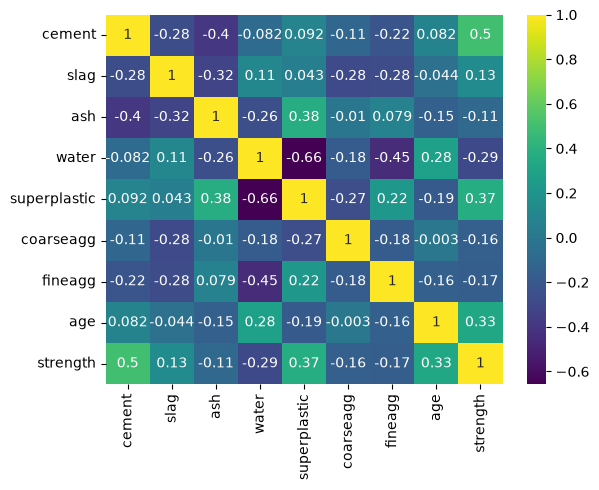

In [30]:
sns.heatmap(correlation,annot=True,cmap='viridis')

# Feature Engineering

In [31]:
## add new column cement and water ratio

In [32]:
concret['cement_water_ratio']=concret['water']/concret['cement']
concret['cement_water_ratio']

0       0.300000
1       0.300000
2       0.685714
3       0.685714
4       0.966767
          ...   
1025    0.649783
1026    0.608318
1027    1.297643
1028    1.103708
1029    0.768877
Name: cement_water_ratio, Length: 1030, dtype: float64

# Hyperparameter tuning

In [33]:
x=concret.drop(columns=['strength'])
y=concret['strength']

In [34]:
model=RandomForestRegressor()

In [35]:
## feture selection

In [39]:
rfe=RFE(model,n_features_to_select=8)
rfe.fit(x,y)
x_selected=concret[x.columns[rfe.get_support(indices=True)]]
x_selected

,cement,slag,water,superplastic,coarseagg,fineagg,age,cement_water_ratio
0,540.0,0.0,162.0,2.5,1040.0,676.0,28,0.300000
1,540.0,0.0,162.0,2.5,1055.0,676.0,28,0.300000
2,332.5,142.5,228.0,0.0,932.0,594.0,270,0.685714
3,332.5,142.5,228.0,0.0,932.0,594.0,365,0.685714
4,198.6,132.4,192.0,0.0,978.4,825.5,360,0.966767
...,...,...,...,...,...,...,...,...
1025,276.4,116.0,179.6,8.9,870.1,768.3,28,0.649783
1026,322.2,0.0,196.0,10.4,817.9,813.4,28,0.608318
1027,148.5,139.4,192.7,6.1,892.4,780.0,28,1.297643
1028,159.1,186.7,175.6,11.3,989.6,788.9,28,1.103708


In [43]:
x_train,x_test,y_train,y_test=train_test_split(x_selected,y,test_size=0.2,random_state=42)

In [44]:
param_grid={'max_depth':[60,50,20,40],'min_samples_split':[8,4,10],'n_estimators':[100, 200]}

In [45]:
grid=GridSearchCV(estimator=model,param_grid=param_grid,scoring='r2',n_jobs=-1)

In [46]:
grid.fit(x_train,y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [60, 50, ...], 'min_samples_split': [8, 4, ...], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the

In [49]:
grid.best_params_

{'max_depth': 50, 'min_samples_split': 4, 'n_estimators': 200}

In [50]:
grid.best_score_

np.float64(0.9055909137316147)

# build model

In [51]:
rf_model=RandomForestRegressor(n_estimators=200,max_depth=50,
    min_samples_split=4)

In [52]:
rf_model.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",50
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",4
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number

In [53]:
y_train_pred=rf_model.predict(x_train)

In [54]:
y_pred=rf_model.predict(x_test)

# Evaluation

In [55]:
mae=mean_absolute_error(y_test,y_pred)
mae

3.8331635826801307

In [56]:
mse=mean_squared_error(y_test,y_pred)
mse

30.02997108256826

In [57]:
rmse=np.sqrt(mse)
rmse

np.float64(5.479960865058095)

In [58]:
r2=r2_score(y_test,y_pred)
r2

0.8834588131901668

In [59]:
r2_train=r2_score(y_train,y_train_pred)
r2_train

0.9821945177030178

## visulaize the model

In [63]:
important_feature=rf_model.feature_importances_
important_feature
feature_names=x_selected.columns
feature_names
list_of_feature=pd.DataFrame({'feature_names':feature_names,'important_score':important_feature})
features=list_of_feature.sort_values(by='important_score',ascending=False)

<Axes: xlabel='important_score', ylabel='feature_names'>

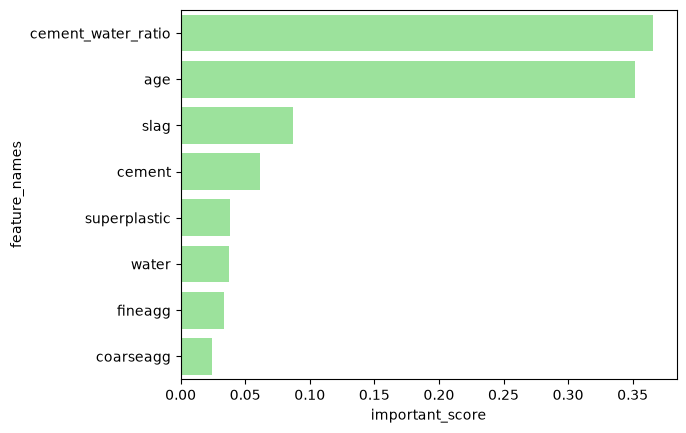

In [64]:
sns.barplot(data=features,
    x='important_score',
    y='feature_names',color='lightgreen')

In [65]:
## plot the decision tree

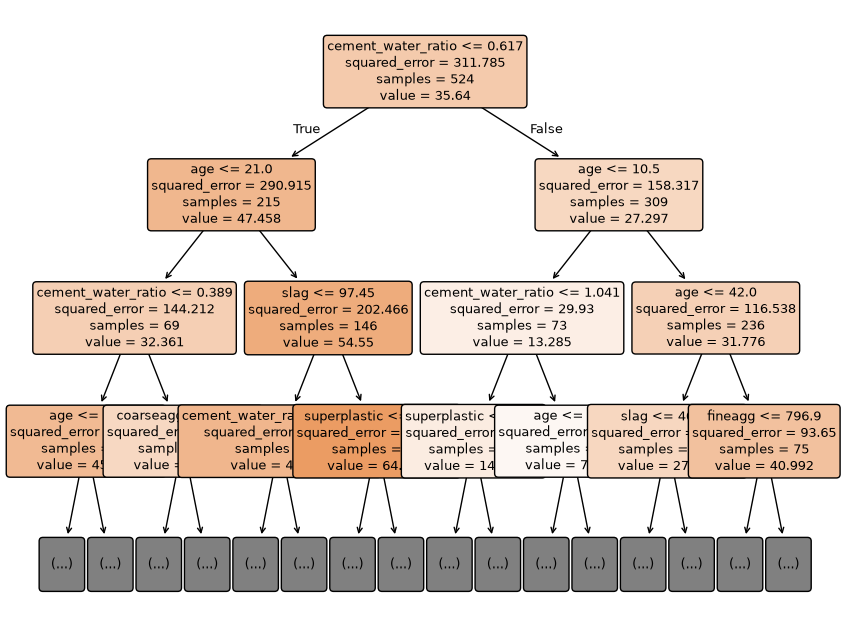

In [66]:
single_tree=rf_model.estimators_[5]

plt.figure(figsize=(10,8))
plot_tree(single_tree,feature_names=feature_names, max_depth=3,            # Clarity-kaga top levels matum paaka (depth adhigama podalam)
    filled=True, 
    rounded=True,
    fontsize=9)

plt.show()

In [67]:
# actual vs predict

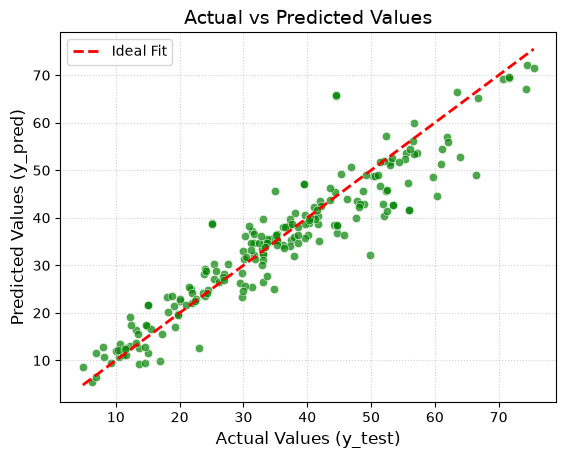

In [68]:
sns.scatterplot(x=y_test,y=y_pred,markers='o',color='green',alpha=0.7)
p1=min(min(y_test),min(y_pred))
p2=max(max(y_test),max(y_pred))
plt.plot([p1,p2],[p1,p2], color='red',linestyle='--', lw=2, label='Ideal Fit')
plt.xlabel("Actual Values (y_test)", fontsize=12)
plt.ylabel("Predicted Values (y_pred)", fontsize=12)
plt.title("Actual vs Predicted Values", fontsize=14)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [69]:
p1

4.83

In [70]:
p2

75.5